# Bank Transaction Classification - Part 1: EDA, Cleaning, Leakage & Label Quality

All logic lives in `txn_pipeline.py` (importable, unit-testable). This notebook only **calls** it, one idea per cell, so every cell can be run on its own after Section 0.

**Sections**
0. Setup
1. Load + data-quality audit
2. Cleaning
3. EDA / data analysis (target, direction, amount, dates, accounts, text)
4. Leakage: split design and audit
5. Label noise: detection, structure, and decision
6. Summary of findings

## 0. Setup
Put `txn_pipeline.py` next to this notebook (in Colab: upload both files, or `%cd` to the folder that has them).

In [1]:
pwd

'/Users/daniyalshaikh/Desktop/Touchstone/assignments/ai_ml/txn_classifier/notebooks'

In [6]:
import sys, os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50); pd.set_option("display.max_colwidth", 70)

sys.path.insert(0, os.getcwd())
from ai_ml.txn_classifier import txn_pipeline as tp

DATA_PATH = '../labeled_transactions.csv'
SEED = tp.RANDOM_SEED
print("using", DATA_PATH)

using ../labeled_transactions.csv


## 1. Load + raw data-quality audit

In [7]:
raw = tp.load_data(DATA_PATH)
print(raw.shape)
raw.head(10)

(3200, 7)


,txn_id,account_number,txn_date,description,amount,txn_type,label
0,T500000,AC100000202,2026-05-29,BROADBAND BILL PAYMENT INITECH,15869.58,debit,utility
1,T500001,AC100000081,2026-08-19,ELECTRICITY BILL PAYMENT,73484.45,debit,utility
2,T500002,AC100000187,2026-05-06,UPI TRANSFER Neha,13277.73,debit,transfer
3,T500003,AC100000064,2026-02-16,IMPS TRANSFER TO Diya,16571.67,debit,transfer
4,T500004,AC100000138,2026-03-15,NEFT TRANSFER Pari,78158.24,credit,transfer
5,T500005,AC100000089,2026-01-20,POS PURCHASE NORTHWIND STORE,22533.99,debit,shopping
6,T500006,AC100000141,2026-05-23,NEFT TRANSFER Ishaan,49552.61,debit,transfer
7,T500007,AC100000075,2026-03-24,EMI AUTO DEBIT SIRIUS CYB LOAN,26257.95,debit,emi
8,T500008,AC100000000,2026-03-12,CLIENT PAYMENT RECEIVED SIRIUS CYB,84217.31,credit,business_receipt
9,T500009,AC100000004,2026-06-23,BROADBAND BILL PAYMENT SIRIUS CYB,52715.69,debit,utility


In [8]:
tp.data_quality_report(raw)

,check,n_rows_affected,status
0,null cells (any column),0,OK
1,duplicate txn_id,0,OK
2,duplicate rows ignoring txn_id,0,OK
3,unparseable dates,0,OK
4,non-numeric amount,0,OK
5,amount <= 0,0,OK
6,"txn_type not in {debit, credit}",0,OK
7,description with leading/trailing/double spaces,0,OK
8,description inconsistent casing of same text,0,OK
9,label with spaces/mixed case,0,OK


**Reading:** no nulls, duplicates, bad dates, non-positive amounts or text-formatting problems. The data is *structurally* clean - so the real quality problem, if any, is in the **labels** (Section 5).

## 2. Cleaning
Standardise types and text, drop unusable rows, add derived columns. **Labels are never altered here.** The returned log is the audit trail.

In [9]:
df, clean_log = tp.clean_transactions(raw)
display(clean_log)
print("clean shape:", df.shape)
df[["txn_id","account_number","txn_date","description","template","amount","txn_type","label"]].head(8)

,step,rows_before,rows_after,rows_removed
0,drop null / unparseable key fields,3200,3200,0
1,drop amount <= 0,3200,3200,0
2,drop invalid txn_type,3200,3200,0
3,drop duplicate txn_id,3200,3200,0
4,drop duplicate rows (ignoring txn_id),3200,3200,0


clean shape: (3200, 12)


,txn_id,account_number,txn_date,description,template,amount,txn_type,label
0,T500000,AC100000202,2026-05-29,BROADBAND BILL PAYMENT INITECH,BROADBAND BILL PAYMENT <CO>,15869.58,debit,utility
1,T500001,AC100000081,2026-08-19,ELECTRICITY BILL PAYMENT,ELECTRICITY BILL PAYMENT,73484.45,debit,utility
2,T500002,AC100000187,2026-05-06,UPI TRANSFER Neha,UPI TRANSFER <NAME>,13277.73,debit,transfer
3,T500003,AC100000064,2026-02-16,IMPS TRANSFER TO Diya,IMPS TRANSFER TO <NAME>,16571.67,debit,transfer
4,T500004,AC100000138,2026-03-15,NEFT TRANSFER Pari,NEFT TRANSFER <NAME>,78158.24,credit,transfer
5,T500005,AC100000089,2026-01-20,POS PURCHASE NORTHWIND STORE,POS PURCHASE <CO> STORE,22533.99,debit,shopping
6,T500006,AC100000141,2026-05-23,NEFT TRANSFER Ishaan,NEFT TRANSFER <NAME>,49552.61,debit,transfer
7,T500007,AC100000075,2026-03-24,EMI AUTO DEBIT SIRIUS CYB LOAN,EMI AUTO DEBIT <CO> LOAN,26257.95,debit,emi


`template` masks company and person names (`SAL CR <CO> PAYROLL`, `IMPS TRANSFER TO <NAME>`). It is used for **analysis and noise detection only**, not as a model feature.

## 3. EDA / data analysis

### 3.1 Target distribution and imbalance

,count,share_pct,imbalance_vs_largest
label,,,
shopping,681,21.28,1.00
salary,485,15.16,1.40
transfer,454,14.19,1.50
utility,330,10.31,2.06
business_receipt,313,9.78,2.18
emi,290,9.06,2.35
rent,274,8.56,2.49
other,171,5.34,3.98
dividend,117,3.66,5.82


{'n_classes': 10, 'largest': 681, 'smallest': 85, 'max_min_ratio': np.float64(8.01), 'normalised_entropy': 0.936}


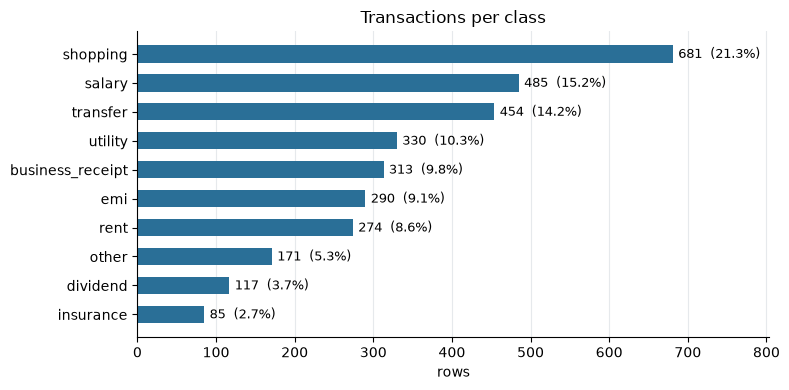

In [10]:
display(tp.class_distribution(df))
print(tp.imbalance_summary(df))
tp.plot_class_distribution(df); plt.show()

**Reading:** 10 classes, mild-to-moderate imbalance (largest/smallest about 8x, normalised entropy 0.94). `insurance` (85) and `dividend` (117) are the minority classes. This is not extreme, so class weighting (not resampling) is the natural first remedy - decided in the modelling step.

### 3.2 Direction (credit/debit) vs label

txn_type,credit,debit
label,,
business_receipt,299,14
dividend,106,11
emi,3,287
insurance,4,81
other,85,86
rent,7,267
salary,476,9
shopping,3,678
transfer,211,243


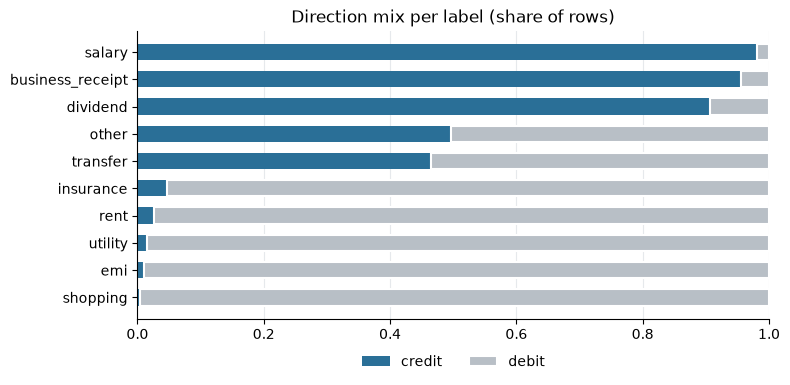

In [11]:
display(tp.type_label_crosstab(df))
tp.plot_direction_by_label(df); plt.show()

**Reading:** direction is a strong, banking-logical signal: `salary`, `business_receipt`, `dividend` are credits; `shopping`, `emi`, `utility`, `rent`, `insurance` are debits; `transfer` and `other` are mixed. The few rows that break this pattern (e.g. salary as a debit) are suspicious - Section 5 uses that.

### 3.3 Amount

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
business_receipt,313.0,44176.0,25474.0,241.0,21414.0,43821.0,64310.0,89974.0
dividend,117.0,49907.0,27421.0,552.0,24538.0,53154.0,75292.0,89921.0
emi,290.0,44216.0,26924.0,489.0,19526.0,44063.0,68110.0,89584.0
insurance,85.0,46945.0,25710.0,960.0,26402.0,40719.0,71443.0,89401.0
other,171.0,47903.0,23886.0,600.0,30094.0,48344.0,68182.0,89779.0
rent,274.0,45593.0,26184.0,355.0,22168.0,45711.0,66862.0,89960.0
salary,485.0,43183.0,25521.0,321.0,21229.0,41895.0,65094.0,89995.0
shopping,681.0,44812.0,26006.0,105.0,22487.0,45021.0,67429.0,89972.0
transfer,454.0,45695.0,26420.0,118.0,22569.0,45876.0,69181.0,89520.0


,value
kruskal_H,11.2821
kruskal_p,0.2569
ks_uniform_stat,0.0105
ks_uniform_p,0.8710


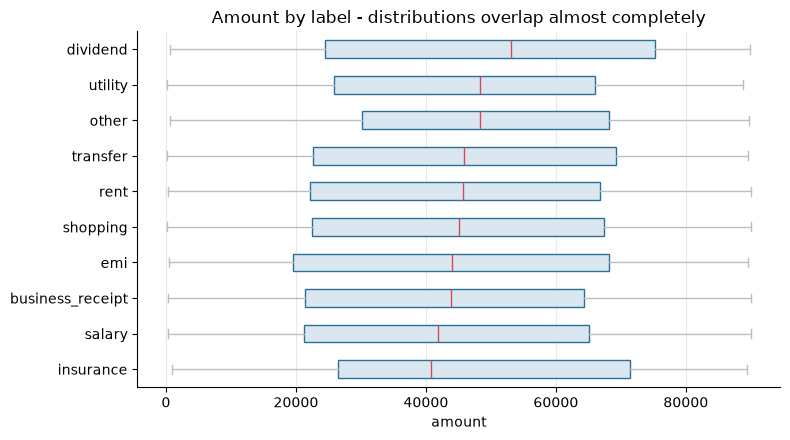

In [12]:
display(tp.amount_by_label(df))
display(pd.Series(tp.amount_signal_tests(df)).round(4).to_frame("value"))
tp.plot_amount_by_label(df); plt.show()

**Reading:** amount looks **uniform between ~100 and ~90,000 for every class** (KS vs uniform p~0.87) and class distributions are statistically indistinguishable (Kruskal p~0.26). In real banking data amount is very informative (salary is large, fees small). Here it carries essentially no signal - an artefact of the synthetic generator. Expect the model to rely on `description`.

In [13]:
tp.domain_sanity_checks(df)

,rule,n_label_rows,n_violations,pct
0,"salary: amount outside [5000, None]",485,31,6.4
1,"rent: amount outside [2000, None]",274,5,1.8
2,"other: amount outside [None, 10000]",171,159,93.0
3,bank fee / service charge booked as CREDIT,113,64,56.6


**Domain check:** 93% of `other` rows (bank fee / service charge / misc) exceed Rs 10k, ~6% of salaries are under Rs 5k, and 57% of bank fees/service charges are booked as credits. These are implausible in real life, confirming amount (and the credit/debit flag *within* `other`) is not trustworthy business signal.

### 3.4 Dates

2026-01-01 -> 2026-08-28


,feature,chi2,dof,p_value
0,month,59.0,63,0.6197
1,day_of_week,58.8,54,0.3040
2,day_of_month_bucket,29.3,36,0.7760


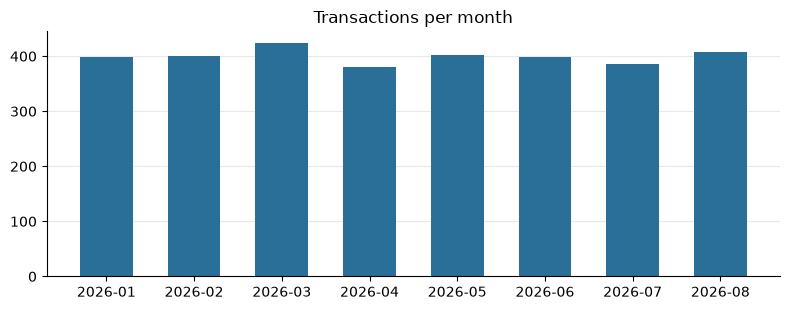

In [14]:
print(df["txn_date"].min().date(), "->", df["txn_date"].max().date())
display(tp.date_signal_tests(df))
tp.plot_monthly_volume(df); plt.show()

**Reading:** Jan-Aug 2026, evenly spread. Label is independent of month, weekday and day-of-month (all p>0.3). Real data would show salary near month end, EMIs on fixed days - absent here. Dates are therefore weak features; they also matter for split design (see 4).

### 3.5 Accounts

,n_txns,n_labels,n_templates,first,last
count,220.0,220.0,220.0,220,220
mean,14.5,6.9,11.0,2026-01-17 04:48:00,2026-08-14 05:27:16.363636480
min,6.0,4.0,5.0,2026-01-01 00:00:00,2026-06-14 00:00:00
25%,12.0,6.0,9.0,2026-01-05 18:00:00,2026-08-09 00:00:00
50%,14.0,7.0,11.0,2026-01-13 00:00:00,2026-08-19 00:00:00
75%,17.0,8.0,12.0,2026-01-23 00:00:00,2026-08-25 00:00:00
max,26.0,9.0,17.0,2026-03-10 00:00:00,2026-08-28 00:00:00
std,3.8,1.2,2.4,NaN,NaN


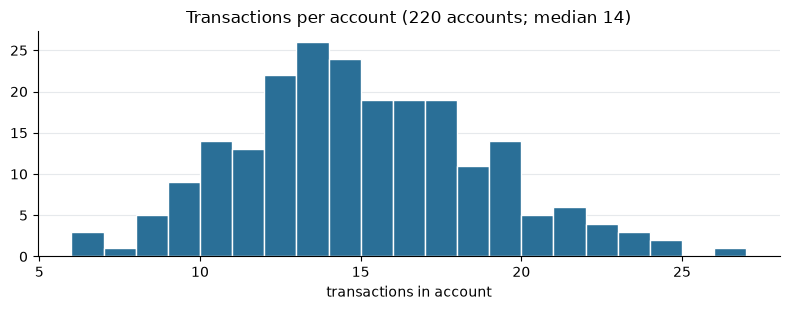

In [15]:
acc = tp.account_summary(df)
display(acc.describe().round(1))
tp.plot_account_sizes(df); plt.show()

**Reading:** 220 accounts, 6-26 transactions each (median 14), each using ~7 of the 10 labels and many different counterparties. Accounts have no 'fixed employer/landlord' identity, but multiple rows per account still means a random row split is unsafe in principle (Section 4).

### 3.6 Description text: templates and counterparties

In [16]:
print("distinct raw descriptions:", df["description"].nunique(), "| distinct templates:", df["template"].nunique())
tt = tp.template_label_table(df)
tt.head(30)

distinct raw descriptions: 313 | distinct templates: 28


,n,majority_label,majority_share,n_labels,minority_labels
template,,,,,
UPI-<CO>-ORDER,256,shopping,0.961,7,"{'insurance': 3, 'business_receipt': 3, 'rent': 1, 'transfer': 1, ..."
ONLINE PURCHASE <CO>,229,shopping,0.961,8,"{'dividend': 2, 'other': 2, 'emi': 1, 'salary': 1, 'insurance': 1,..."
POS PURCHASE <CO> STORE,216,shopping,0.954,7,"{'business_receipt': 5, 'transfer': 1, 'salary': 1, 'dividend': 1,..."
SALARY CREDIT <CO>,169,salary,0.988,3,"{'other': 1, 'transfer': 1}"
SAL CR <CO> PAYROLL,168,salary,0.929,8,"{'transfer': 3, 'business_receipt': 2, 'rent': 2, 'emi': 2, 'insur..."
NEFT TRANSFER <NAME>,163,transfer,0.957,7,"{'rent': 2, 'shopping': 1, 'other': 1, 'business_receipt': 1, 'sal..."
<CO> SALARY DISBURSEMENT,152,salary,0.974,5,"{'shopping': 1, 'utility': 1, 'rent': 1, 'transfer': 1}"
IMPS TRANSFER TO <NAME>,152,transfer,0.961,5,"{'business_receipt': 2, 'insurance': 2, 'utility': 1, 'salary': 1}"
UPI TRANSFER <NAME>,148,transfer,0.932,6,"{'other': 3, 'dividend': 2, 'insurance': 2, 'shopping': 2, 'salary..."


**Reading (the key EDA finding):** descriptions are generated from just **28 templates** plus a counterparty. Nearly every template maps to one label ~93-100% of the time - **but almost every template also has a few rows with an unrelated label** (e.g. `ONLINE PURCHASE <CO>` labelled `salary`). That is the first sign of label noise.

## 4. Data leakage

**Risks considered**

| Risk | How it is handled |
|---|---|
| Same account in train and test (rows of one customer are correlated) | `group_train_test_split`: stratified, **grouped by `account_number`** |
| Identifier columns encoding the label (`txn_id` order, account id) | `id_label_association` tests; IDs are never model features |
| Duplicate transactions straddling the split | `leakage_audit` checks exact (description, amount, type) overlap |
| Features computed on the full dataset (account aggregates, TF-IDF vocab, class weights, target encodings) | Must be **fit on train only** inside a Pipeline / CV fold - enforced in the modelling step |
| Label noise cleaned using test rows | Noise detection below uses out-of-fold scores; the test set is left untouched |

In [17]:
display(tp.id_label_association(df, ["txn_id", "account_number"]))
display(tp.account_memorisation_probe(df))

,column,chi2,dof,p_value,verdict
0,txn_id,67.3,81,0.8623,no association
1,account_number,92.9,81,0.1724,no association


,strategy,accuracy
0,majority-class baseline,0.1983
1,"account-only, RANDOM split",0.1328
2,"account-only, GROUPED split",0.1983


**Reading:** neither the running id nor the account id is associated with the label. The account-only probe never beats the majority baseline (it does *worse* under a random split), so accounts do not leak label information in this dataset. We still split by account because production data would be scored on **new customers**, and an honest estimate must mimic that.

In [18]:
train, test = tp.group_train_test_split(df, test_size=0.2, seed=SEED)
print(f"train {len(train)} rows / {train.account_number.nunique()} accounts | "
      f"test {len(test)} rows / {test.account_number.nunique()} accounts")
tp.assert_no_group_overlap(train, test)      # raises if an account leaks
display(tp.leakage_audit(train, test))
display(tp.class_balance_across_split(train, test))

train 2600 rows / 177 accounts | test 600 rows / 43 accounts


,check,value,expectation,status
0,accounts shared between train and test,0.0,must be 0,OK
1,txn_ids shared between train and test,0.0,must be 0,OK
2,"identical (description, amount, txn_type) in both",0.0,must be 0,OK
3,% test rows whose exact description appears in train,98.7,expected high (templated text),OK
4,% test rows whose TEMPLATE appears in train,100.0,expected ~100,OK


,train_pct,test_pct,abs_diff
label,,,
shopping,21.62,19.83,1.79
salary,15.58,13.33,2.25
transfer,14.38,13.33,1.05
utility,10.31,10.33,0.02
business_receipt,9.38,11.50,2.12
emi,8.92,9.67,0.75
rent,8.81,7.50,1.31
other,5.19,6.00,0.81
dividend,3.42,4.67,1.25


**Reading:** zero shared accounts, txn_ids or duplicate transactions; class proportions in train/test differ by <0.7 pt. Description *templates* overlap ~100% - expected and legitimate, because the same bank wording recurs across customers.

## 5. Label / data quality - is there label noise?

Three **independent-looking** signals (none modifies a label):

* **A. Template disagreement** - same description template, different label than its dominant label (needs >=5 rows and >=80% majority).
* **B. Direction conflict** - a (label, credit/debit) combination covering <5% of that label (e.g. salary booked as debit).
* **C. Model disagreement (Confident Learning)** - out-of-fold TF-IDF + logistic regression with account-grouped CV; the row's label is unlikely given what the text says.

`suspect` = at least two signals. All are for **flagging**, not for rewriting labels.

In [19]:
report, conf_joint, cl_rate = tp.label_issue_report(df, seed=SEED)
sig_table, sig_overlap = tp.signal_agreement(report)
display(sig_table)
display(sig_overlap)
print(f"Confident-learning estimate of overall noise rate: {cl_rate:.1%}")

,n_flagged,pct
signal,,
sig_template,128,4.00
sig_direction,45,1.41
sig_model,110,3.44
any signal,128,4.00
>=2 signals (suspect),116,3.62


,sig_template,sig_direction,sig_model
sig_template,128,45,110
sig_direction,45,45,39
sig_model,110,39,110


Confident-learning estimate of overall noise rate: 4.2%


**Reading:** about **4% of labels (128 / 3,200) contradict their description**. The signals corroborate: all 109 model-flagged rows are also template-flagged, and the direction check independently flags 45 of the same rows. *Caveat:* signals A and C both read the description, so they are not fully independent; B is the independent one, and it agrees.

In [20]:
display(tp.review_queue(report, top_n=20))

,txn_id,account_number,description,txn_type,amount,label,tmpl_majority,model_label,p_given_label,n_signals
2076,T502076,AC100000215,BUSINESS RECEIPT GLOBEX,credit,88185.65,shopping,business_receipt,business_receipt,0.0001,3
2880,T502880,AC100000022,LOAN EMI HOOLI,debit,77694.03,salary,emi,emi,0.0001,3
394,T500394,AC100000031,BANK FEE,debit,20453.14,business_receipt,other,other,0.0002,3
942,T500942,AC100000016,SAL CR INITECH PAYROLL,credit,36404.72,insurance,salary,salary,0.0002,3
1383,T501383,AC100000082,IMPS TRANSFER TO Arjun,credit,52597.49,utility,transfer,transfer,0.0002,3
2760,T502760,AC100000202,IMPS TRANSFER TO Neha,debit,25224.00,salary,transfer,transfer,0.0002,3
1417,T501417,AC100000025,HOOLI SALARY DISBURSEMENT,credit,55719.88,shopping,salary,salary,0.0003,3
2052,T502052,AC100000199,WAYNE ENT SALARY DISBURSEMENT,credit,80908.14,utility,salary,salary,0.0003,3
2501,T502501,AC100000010,DIVIDEND CREDIT GLOBEX MF,credit,71590.18,rent,dividend,dividend,0.0003,3
2950,T502950,AC100000171,SERVICE CHARGE,credit,25593.35,emi,other,other,0.0003,3


These are obvious errors: a `SALARY DISBURSEMENT` credit labelled `shopping`, an `ONLINE PURCHASE` debit labelled `salary`, a `BANK FEE` labelled `business_receipt`.

### 5.1 Where is the noise?

,n_flagged,n_rows,flag_rate_pct
label,,,
insurance,15,85,17.6
dividend,15,117,12.8
other,11,171,6.4
business_receipt,19,313,6.1
rent,14,274,5.1
utility,11,330,3.3
transfer,14,454,3.1
salary,14,485,2.9
emi,6,290,2.1


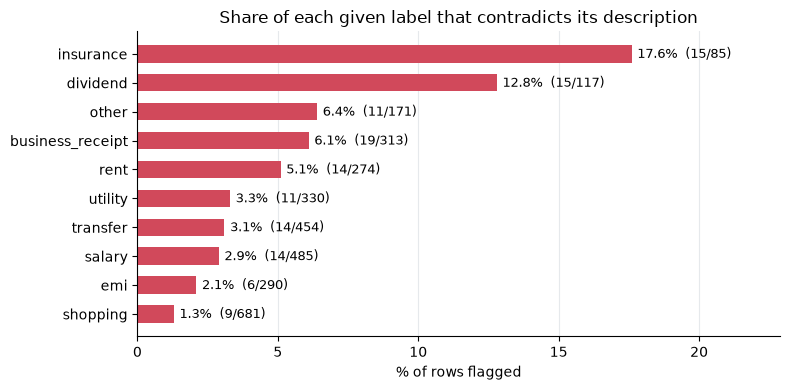

In [21]:
nbc = tp.noise_by_class(report)
display(nbc)
tp.plot_noise_by_class(nbc); plt.show()

**Reading:** the *rate* is highest for the smallest classes (`insurance` 17.6%, `dividend` 12.8%) and lowest for the largest (`shopping` 1.3%). Absolute counts are similar (6-19 per class), which is what uniform random flipping looks like - the same number of flips is a much bigger share of a small class. **This matters:** small classes are exactly the ones we most need to get right, and they suffer most from noise.

given label,business_receipt,dividend,emi,insurance,other,rent,salary,shopping,transfer,utility
expected (template majority),,,,,,,,,,
business_receipt,0,1,0,2,0,2,1,1,2,2
dividend,0,0,0,0,0,1,0,0,1,0
emi,1,2,0,2,2,3,3,1,0,2
insurance,0,0,0,0,0,1,0,1,0,2
other,1,0,1,0,0,0,3,1,2,1
rent,0,1,0,1,0,0,0,0,1,1
salary,2,1,2,1,1,3,0,1,5,2
shopping,9,3,3,4,3,1,3,0,3,0
transfer,3,2,0,5,4,2,3,3,0,1


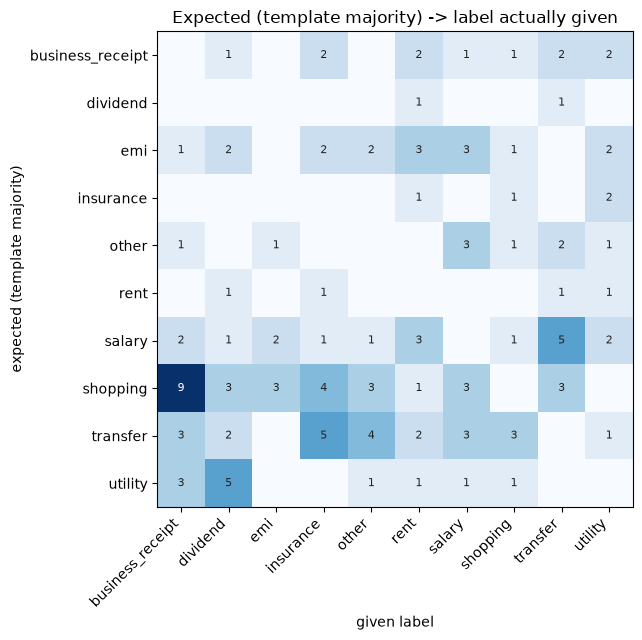

{'n_flagged': 128, 'chi2_vs_uniform': 9.34375, 'p_value': 0.4061670148926163, 'min_class': 6, 'max_class': 19}


In [22]:
fm = tp.flip_matrix(report)
display(fm)
tp.plot_heatmap(fm, "Expected (template majority) -> label actually given"); plt.show()
print(tp.flip_destination_uniformity(report))

**Reading:** flips are spread across many class pairs and land roughly evenly across all classes (chi-square vs uniform p~0.41). No single systematic confusion (e.g. 'rent' vs 'transfer') dominates.

In [23]:
display(tp.noise_structure(report))

,test,p_value,reading
0,amount: flagged vs clean (Mann-Whitney),0.935137,consistent with random
1,direction (txn_type): chi-square independence,0.931681,consistent with random
2,month: chi-square independence,0.251974,consistent with random
3,account clustering of flags (permutation),0.906500,consistent with random


**Reading:** flagged rows are independent of amount, direction, month and account (all p>0.2). Together with the even spread above, the noise looks like **random (class-independent) label flipping at ~4%**, not a systematic labelling policy. Random noise at this level degrades but does not bias a model badly; systematic noise would be much worse.

### 5.2 Decision on handling (to be applied in the modelling step)

| Choice | Decision | Why |
|---|---|---|
| Relabel automatically | **No** | The template/model "correct" label is a guess; real data can have genuine exceptions (e.g. a rent payment sent via NEFT). Auto-relabelling would hide the problem and bake in our own bias. |
| Test set | **Keep labels untouched**, report metrics against the given labels, and additionally report on the non-suspect subset | Gives an honest view and shows how much of the error is label noise rather than model error. |
| Training set | Train on all rows **and** on train minus `suspect` rows (>=2 signals); compare | At ~3.6% suspect rows the data is cheap to drop. The experiment tells us whether it helps. Flags come from out-of-fold scores so no test information is used. |
| Human review | Send the review queue (highest signal count, lowest `p_given_label`) to an annotator | Cheapest way to fix labels for good. Feeds the optional active-learning idea. |

In [24]:
kept, quarantined = tp.split_suspects(report, min_signals=2)
print(f"kept {len(kept)} rows, quarantined {len(quarantined)} ({len(quarantined)/len(report):.1%})")
quarantined.label.value_counts().to_frame("quarantined_rows")

kept 3084 rows, quarantined 116 (3.6%)


,quarantined_rows
label,
business_receipt,19
rent,13
salary,13
dividend,13
insurance,13
utility,11
other,10
transfer,10
shopping,8


## 6. Summary of findings (Part 1)

* **Data hygiene:** clean - 3,200 rows, 220 accounts, no nulls/duplicates/invalid values. Nothing dropped in cleaning.
* **Imbalance:** 10 classes, 8x ratio (shopping 681 -> insurance 85). Moderate.
* **Signals:** `description` is by far the strongest signal (28 templates x counterparty); `txn_type` is a useful logical check; `amount` and date carry **no** signal (uniform, independent of label, domain-implausible) - this is a synthetic-data artefact.
* **Leakage:** handled by an account-grouped, stratified split with an automated audit; IDs and accounts do not encode the label.
* **Label noise: yes, ~4% (about 128 rows)**, apparently random and class-independent, hitting small classes hardest (insurance 17.6%, dividend 12.8% of rows). Labels are flagged, not edited; the decision rule is in 5.2.
* **Implication for evaluation:** since ~4% of test labels are likely wrong, accuracy near ~96% is effectively the **ceiling** on the raw test labels. Per-class scores for `insurance` and `dividend` will look worse than the model really is.

